# Bước 7 – 8: Giải thích mô hình (SHAP) & Hỗ trợ quyết định kinh doanh
## Bộ đặc trưng chính (14 cột: RFM mở rộng + Tenure/AvgInterval + Is_UK)

**Lưu ý quan trọng trước khi bắt đầu:**

Bộ đặc trưng dùng trong notebook này gồm **14 cột**: RFM mở rộng (Recency, Frequency, Monetary, AvgOrderValue, NumProducts), nhịp độ mua (`IntervalStd`, `AvgInterval`), xu hướng (`SpendingTrend`, `FrequencyTrend`), `CancelRate`, `ActiveMonths`/`RepeatPurchaseRatio`, `Tenure`, và biến địa lý nhị phân `Is_UK`. Để kiểm tra độ nhạy với cách mã hóa địa lý, nhóm cũng đã đánh giá riêng một biến thể thay `Is_UK` bằng one-hot 8 quốc gia (19 cột) trên cùng 8 fold walk-forward × 4 mô hình (xem `03-du-lieu/ket-qua-mo-hinh-that/so-sanh-bo-dac-trung-A-B_REAL.csv`): mã hóa chi tiết hơn chỉ cải thiện có ý nghĩa thống kê trên Logistic Regression (p = 0.016), không có ý nghĩa trên các mô hình dạng cây — nên `Is_UK` được giữ làm biến địa lý chính cho toàn bộ phân tích SHAP/Business Decision Support dưới đây (mô hình chính — RandomForest — không hưởng lợi từ mã hóa chi tiết hơn).

Notebook này áp dụng **SHAP (Bước 7)** và **bảng hỗ trợ quyết định kinh doanh (Bước 8)** lên bộ đặc trưng 14 cột nói trên.

**Quy trình**: huấn luyện lại mô hình tốt nhất (chọn bằng ROC-AUC trên tập Validation) ngay trên pipeline walk-forward đã kiểm định — **không** dùng một tách train/test tĩnh riêng biệt như phần lớn tài liệu tham khảo vẫn làm. 1 mô hình (RandomForest — theo kết quả thật đã chạy, xem mục 1.3), phân tích chi tiết (global/dependence/local/bảng quyết định) trên 1 fold đại diện (Test = 2011-06-01, fold ở giữa 8 fold), và kiểm tra độ ổn định của thứ hạng đặc trưng trên **cả 8 fold** (mục 3.1b).

### 0.1. Các điều chỉnh sau khi rà soát code (so với bản trước)

Bản notebook trước đã được rà soát lại (code review) và phát hiện 3 điểm cần sửa để **chính xác và an toàn hơn**, không làm thay đổi kết quả mô hình (ROC-AUC, PR-AUC, bảng xếp hạng SHAP không đổi):

1. **Mục 3 (SHAP)** — câu giải thích `base_value` trước đây quy sai nguyên nhân chênh lệch giữa base_value (≈0.50) và tỷ lệ churn thật (≈0.67) là do "xác suất dự đoán trung bình khác nhãn thật". Nguyên nhân thật là **`class_weight='balanced'`** (mục 2) khiến các lá cây được tính lại theo hướng cân bằng 50/50 giữa 2 lớp — đã sửa lại đúng nguyên nhân và nói rõ `churn_prob` là **điểm số xếp hạng rủi ro**, không phải xác suất đã hiệu chỉnh (calibrated).
2. **Mục 4 (Bước 8, hàm `top_drivers`)** — trước đây, với khách hàng mà **toàn bộ 14 giá trị SHAP đều ≤ 0** (không có yếu tố nào đẩy churn lên — đây là nhóm khách **an toàn nhất**), hàm cũ vẫn chọn ra 1 đặc trưng (có `|SHAP|` lớn nhất, nhưng là giá trị **âm**, tức đang *bảo vệ* khách khỏi churn) rồi gán nhãn kinh doanh như thể đó là nguyên nhân gây churn — sai logic. Đã sửa: nhóm khách hàng này (2/4.909 khách, 0.04%) nay được gán nhãn riêng **"Khách hàng an toàn"**, không tra `DRIVER_MAP` nữa.
3. **Mục 3 (tách lớp SHAP)** — `shap_values_raw.values[:, :, 1]` giả định cứng SHAP luôn trả về mảng 3 chiều; đã thêm kiểm tra `ndim` để notebook vẫn chạy đúng nếu phiên bản thư viện `shap` khác trả về định dạng khác.

### 0.2. Bổ sung: mở rộng SHAP sang toàn bộ 8 fold

Bản trước chỉ chạy SHAP trên 1 fold đại diện (Test=2011-06-01), nêu rõ đây là hạn chế cần mở rộng (mục 5, điểm 3). Đã bổ sung mục **3.1b** — lặp lại quy trình chọn hyperparameter + huấn luyện RandomForest (seed=0) + tính TreeSHAP cho **cả 8 fold**, tổng hợp |SHAP| trung bình ± độ lệch chuẩn và số fold mỗi đặc trưng lọt Top-5 quan trọng nhất. Kết quả xác nhận 5 đặc trưng dẫn đầu ổn định qua thời gian (6–8/8 fold), và củng cố chắc chắn hơn hai phát hiện đã có: `Tenure` dư thừa, `Is_UK` đóng góp rất ít. Các mục 3.1, 3.2, 3.3, 4 phía dưới **giữ nguyên không đổi** — vẫn minh họa chi tiết (global/dependence/local/bảng quyết định) trên 1 fold đại diện, vì bảng quyết định cấp khách hàng theo bản chất gắn với một mốc thời gian cụ thể, không gộp được qua nhiều fold.

## 1. Chuẩn bị dữ liệu và đặc trưng (Bộ B)

### 1.1. Đọc và làm sạch dữ liệu

Dùng lại đúng hàm `lam_sach_du_lieu()` đã kiểm định trong `eda-va-tien-xu-ly-du-lieu.ipynb`. Đường dẫn đổi thành đường dẫn **tương đối** `../03-du-lieu/du-lieu-tho/online_retail_II_raw.csv.gz` (notebook gốc `churn-pipeline-BO-B-thu-nghiem-KHONG-dung.ipynb` trỏ cứng vào ổ đĩa Windows cá nhân — không chạy được ở máy khác, nên notebook này sửa lại để bất kỳ thành viên nào trong nhóm cũng chạy lại được).

In [1]:
import pandas as pd
import numpy as np
import os
import warnings
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import wilcoxon
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_recall_curve,
                              precision_score, recall_score, f1_score, confusion_matrix)
import xgboost as xgb
import lightgbm as lgb
import shap

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_context("paper", font_scale=1.2)

print("Tat ca thu vien da san sang (bo sung so voi pipeline Buoc 4-6: them 'shap').")

Tat ca thu vien da san sang (bo sung so voi pipeline Buoc 4-6: them 'shap').


In [2]:
RAW_PATH = '../03-du-lieu/du-lieu-tho/online_retail_II_raw.csv.gz'

df_raw = pd.read_csv(RAW_PATH, encoding='ISO-8859-1', compression='gzip')
df_raw['InvoiceDate'] = pd.to_datetime(df_raw['InvoiceDate'])

if 'CustomerID' in df_raw.columns:
    df_raw = df_raw.rename(columns={'CustomerID': 'Customer ID'})
df_raw['is_cancelled'] = df_raw['Invoice'].astype(str).str.startswith('C')

def lam_sach_du_lieu(df_input):
    df = df_input.copy()
    df['Invoice'] = df['Invoice'].astype(str)
    df = df[~df['Invoice'].str.startswith('C')]
    non_product_codes = ['POST', 'D', 'M', 'BANK CHARGES', 'DOT', 'ADJUST', 'ADJUST2', 'CRUK']
    df = df[~df['StockCode'].astype(str).isin(non_product_codes)]
    df = df.dropna(subset=['Customer ID'])
    df = df[(df['Quantity'] > 0) & (df['Price'] > 0)]
    df = df.drop_duplicates()
    df['Revenue'] = df['Quantity'] * df['Price']
    return df.reset_index(drop=True)

df_clean = lam_sach_du_lieu(df_raw)
print("Kich thuoc du lieu goc (+is_cancelled):", df_raw.shape)
print("Kich thuoc sau lam sach (+Revenue)   :", df_clean.shape)
assert df_clean.shape[0] == 776854, "So dong sau lam sach khong khop voi bao cao EDA — kiem tra lai nguon du lieu!"
print("Khop voi bao-cao-eda-thuc-te.md (776.854 dong).")

Kich thuoc du lieu goc (+is_cancelled): (1067371, 9)
Kich thuoc sau lam sach (+Revenue)   : (776854, 10)
Khop voi bao-cao-eda-thuc-te.md (776.854 dong).


### 1.2. Feature engineering — Bộ B (14 cột)

Giống hệt logic trong `churn-pipeline-BO-B-thu-nghiem-KHONG-dung.ipynb`: RFM lõi + `Tenure` + nhịp độ mua (`IntervalStd`, `AvgInterval`) + xu hướng (`SpendingTrend`, `FrequencyTrend`) + `CancelRate` + `RepeatPurchaseRatio` (qua `ActiveMonths`) + **`Is_UK`** (gộp địa lý thành 1 cột nhị phân, thay cho 8 cột One-Hot quốc gia của Bộ A).

In [3]:
def tinh_rfm_va_tenure(df_clean_input, cutoff_date):
    obs = df_clean_input[df_clean_input['InvoiceDate'] < cutoff_date]
    rfm = obs.groupby('Customer ID').agg(
        Recency=('InvoiceDate', lambda x: (cutoff_date - x.max()).days),
        Frequency=('Invoice', 'nunique'),
        Monetary=('Revenue', 'sum'),
        AvgOrderValue=('Revenue', 'mean'),
        NumProducts=('StockCode', 'nunique'),
        FirstPurchase=('InvoiceDate', 'min'),
        Country=('Country', lambda x: x.mode().iloc[0] if not x.mode().empty else 'Unknown')
    ).reset_index()
    rfm['Tenure'] = (cutoff_date - rfm['FirstPurchase']).dt.days
    return rfm

def them_nhip_do_mua_sam(rfm_df, obs_df):
    def std_khoang_cach(dates):
        d = np.sort(dates.unique())
        if len(d) < 3: return np.nan
        return float(np.std(np.diff(d) / np.timedelta64(1, 'D')))

    def avg_khoang_cach(dates):
        d = np.sort(dates.unique())
        if len(d) < 2: return np.nan
        return float(np.mean(np.diff(d) / np.timedelta64(1, 'D')))

    interval_std = obs_df.groupby('Customer ID')['InvoiceDate'].apply(std_khoang_cach).rename('IntervalStd').reset_index()
    interval_avg = obs_df.groupby('Customer ID')['InvoiceDate'].apply(avg_khoang_cach).rename('AvgInterval').reset_index()

    out = rfm_df.merge(interval_std, on='Customer ID', how='left').merge(interval_avg, on='Customer ID', how='left')
    out['IntervalStd'] = out['IntervalStd'].fillna(out['IntervalStd'].median())
    out['AvgInterval'] = out['AvgInterval'].fillna(out['AvgInterval'].median())
    return out

def them_xu_huong(rfm_df, obs_df, cutoff_date):
    mid_point = cutoff_date - pd.Timedelta(days=90)
    far_point = cutoff_date - pd.Timedelta(days=180)

    rev_recent = obs_df[obs_df['InvoiceDate'] >= mid_point].groupby('Customer ID')['Revenue'].sum()
    rev_prev = obs_df[(obs_df['InvoiceDate'] >= far_point) & (obs_df['InvoiceDate'] < mid_point)].groupby('Customer ID')['Revenue'].sum()
    freq_recent = obs_df[obs_df['InvoiceDate'] >= mid_point].groupby('Customer ID')['Invoice'].nunique()
    freq_prev = obs_df[(obs_df['InvoiceDate'] >= far_point) & (obs_df['InvoiceDate'] < mid_point)].groupby('Customer ID')['Invoice'].nunique()

    trend = pd.concat([rev_recent.rename('rev_recent'), rev_prev.rename('rev_prev'),
                       freq_recent.rename('freq_recent'), freq_prev.rename('freq_prev')], axis=1).fillna(0)
    trend['SpendingTrend'] = trend['rev_recent'] - trend['rev_prev']
    trend['FrequencyTrend'] = trend['freq_recent'] - trend['freq_prev']
    trend = trend[['SpendingTrend', 'FrequencyTrend']].reset_index()

    out = rfm_df.merge(trend, on='Customer ID', how='left')
    out[['SpendingTrend', 'FrequencyTrend']] = out[['SpendingTrend', 'FrequencyTrend']].fillna(0)
    return out

def them_cancel_rate(rfm_df, df_raw_input, cutoff_date):
    obs_raw = df_raw_input[df_raw_input['InvoiceDate'] < cutoff_date]
    total = obs_raw.groupby('Customer ID')['Invoice'].nunique().rename('TotalInvoices')
    cancelled = obs_raw[obs_raw['is_cancelled']].groupby('Customer ID')['Invoice'].nunique().rename('CancelledInvoices')

    c = pd.concat([total, cancelled], axis=1).fillna(0)
    c['CancelRate'] = c['CancelledInvoices'] / c['TotalInvoices'].replace(0, np.nan)
    c = c[['CancelRate']].fillna(0).reset_index()
    out = rfm_df.merge(c, on='Customer ID', how='left')
    out['CancelRate'] = out['CancelRate'].fillna(0)
    return out

def them_repeat_purchase_ratio(rfm_df, obs_df, cutoff_date):
    tenure_months = ((cutoff_date - rfm_df['FirstPurchase']).dt.days / 30.44).clip(lower=1)
    active_months = obs_df.assign(ym=obs_df['InvoiceDate'].dt.to_period('M')).groupby('Customer ID')['ym'].nunique().rename('ActiveMonths')
    out = rfm_df.merge(active_months, on='Customer ID', how='left')
    out['ActiveMonths'] = out['ActiveMonths'].fillna(1)
    out['RepeatPurchaseRatio'] = (out['ActiveMonths'] / tenure_months).clip(upper=1.0)
    return out

def tinh_dac_trung_nang_cao(df_raw_input, df_clean_input, cutoff_date):
    obs_clean = df_clean_input[df_clean_input['InvoiceDate'] < cutoff_date].copy()
    features = tinh_rfm_va_tenure(df_clean_input, cutoff_date)
    features = them_nhip_do_mua_sam(features, obs_clean)
    features = them_xu_huong(features, obs_clean, cutoff_date)
    features = them_cancel_rate(features, df_raw_input, cutoff_date)
    features = them_repeat_purchase_ratio(features, obs_clean, cutoff_date)
    features['Is_UK'] = (features['Country'] == 'United Kingdom').astype(int)
    return features.drop(columns=['FirstPurchase', 'Country'])

print("Da dinh nghia xong ham dac trung Bo B (Tenure, AvgInterval, Is_UK).")

Da dinh nghia xong ham dac trung Bo B (Tenure, AvgInterval, Is_UK).


### 1.3. Gán nhãn churn + tạo 8 fold walk-forward

Giữ nguyên thiết kế đã kiểm định ở Bước 4-5 (cửa sổ churn = 90 ngày, khoảng cách Train→Val→Test đúng bằng cửa sổ churn để tránh leakage, 8 mốc Test cách nhau 1 tháng từ 2011-02-01 đến 2011-09-01).

In [4]:
max_date = df_clean['InvoiceDate'].max()

def kiem_tra_va_gan_nhan(df_clean_input, cutoff_date, churn_window_days, max_date_input):
    required_end = cutoff_date + pd.Timedelta(days=churn_window_days)
    if required_end > max_date_input: return None, False

    obs = df_clean_input[df_clean_input['InvoiceDate'] < cutoff_date]
    future = df_clean_input[(df_clean_input['InvoiceDate'] >= cutoff_date) & (df_clean_input['InvoiceDate'] < required_end)]
    customers_before = obs['Customer ID'].unique()
    if len(customers_before) == 0: return None, False

    active_future = set(future['Customer ID'].unique())
    labels = pd.Series([0 if cid in active_future else 1 for cid in customers_before], index=customers_before, name='churn')
    return labels, True

def tao_cac_fold(window_months, test_cutoffs):
    return [(t - pd.DateOffset(months=2 * window_months),
             t - pd.DateOffset(months=window_months), t) for t in test_cutoffs]

test_cutoffs_3m = [pd.Timestamp('2011-02-01') + pd.DateOffset(months=i) for i in range(8)]
folds_3m = tao_cac_fold(3, test_cutoffs_3m)

print("8 fold thoi gian chuan (Train - Val - Test):")
for tr, va, te in folds_3m:
    print(f"  Train={tr.date()} | Val={va.date()} | Test={te.date()}")

def data_tai_cutoff(cutoff, window_days=90):
    feats = tinh_dac_trung_nang_cao(df_raw, df_clean, cutoff)
    labels, is_valid = kiem_tra_va_gan_nhan(df_clean, cutoff, window_days, max_date)
    if not is_valid: return None
    return feats.merge(labels.rename('churn'), left_on='Customer ID', right_index=True)

feature_cols = [c for c in data_tai_cutoff(pd.Timestamp('2010-08-01')).columns if c not in ('Customer ID', 'churn')]
print(f"\nSo dac trung Bo B: {len(feature_cols)}")
print(feature_cols)

8 fold thoi gian chuan (Train - Val - Test):
  Train=2010-08-01 | Val=2010-11-01 | Test=2011-02-01
  Train=2010-09-01 | Val=2010-12-01 | Test=2011-03-01
  Train=2010-10-01 | Val=2011-01-01 | Test=2011-04-01
  Train=2010-11-01 | Val=2011-02-01 | Test=2011-05-01
  Train=2010-12-01 | Val=2011-03-01 | Test=2011-06-01
  Train=2011-01-01 | Val=2011-04-01 | Test=2011-07-01
  Train=2011-02-01 | Val=2011-05-01 | Test=2011-08-01
  Train=2011-03-01 | Val=2011-06-01 | Test=2011-09-01



So dac trung Bo B: 14
['Recency', 'Frequency', 'Monetary', 'AvgOrderValue', 'NumProducts', 'Tenure', 'IntervalStd', 'AvgInterval', 'SpendingTrend', 'FrequencyTrend', 'CancelRate', 'ActiveMonths', 'RepeatPurchaseRatio', 'Is_UK']


### 1.4. Kết quả walk-forward đầy đủ đã chạy (tham chiếu)

Để chọn đúng mô hình tốt nhất cho SHAP, dưới đây là kết quả thật đã chạy đủ 8 fold × 4 mô hình trên Bộ B (trích từ `churn-pipeline-BO-B-thu-nghiem-KHONG-dung.ipynb`, không chạy lại ở đây để tiết kiệm thời gian — phần huấn luyện lại ở mục 2 chỉ chạy trên **1 fold đại diện**):

| Mô hình | ROC-AUC (TB ± SD, 8 fold) | PR-AUC |
|---|---|---|
| LogisticRegression | 0.790 ± 0.011 | 0.849 |
| **RandomForest** | **0.797 ± 0.015** | **0.853** |
| XGBoost | 0.766 ± 0.022 | 0.826 |
| LightGBM | 0.769 ± 0.020 | 0.830 |

→ **RandomForest** là mô hình tốt nhất trên Bộ B (thắng Logistic Regression ở 7/8 fold nhưng p=0.055 — chưa đạt ý nghĩa thống kê ở mức 0.05; thắng rõ rệt XGBoost và LightGBM với p=0.0078). Notebook này chạy SHAP trên **RandomForest**.

## 2. Huấn luyện lại RandomForest trên 1 fold đại diện

Chọn fold **Test = 2011-06-01** (Train=2010-12-01, Val=2011-03-01) — fold nằm giữa 8 fold, không phải fold đầu/cuối dễ bị nhiễu bởi hiệu ứng biên dữ liệu. Quy trình chọn hyperparameter giữ nguyên: 2 cấu hình, chọn theo ROC-AUC trên Validation; ngưỡng phân loại chọn theo F1 tối đa trên Validation.

**Vì sao `class_weight='balanced'`?** Churn ở đây là lớp **đa số** (~65-67%, không phải thiểu số như giả định thường thấy) — dùng `class_weight='balanced'` để RandomForest không thiên vị đơn giản về phía lớp đa số. Lưu ý quan trọng (xem mục 0.1 và mục 3): việc này khiến xác suất dự đoán của mô hình bị "kéo" về gần ngưỡng 0.5, nên `churn_prob` nên được đọc là **điểm số xếp hạng rủi ro**, không phải xác suất churn đã hiệu chỉnh theo đúng tỷ lệ thật.

In [5]:
model_configs = {
    'RandomForest': {
        'builder': lambda p, seed: RandomForestClassifier(random_state=seed, class_weight='balanced', n_jobs=-1, **p),
        'param_grid': [{'n_estimators': 200, 'max_depth': 5}, {'n_estimators': 300, 'max_depth': 8}],
        'needs_scaling': False, 'seeds': (0, 1, 2)
    }
}

def nguong_toi_uu_f1(y_true, y_prob):
    precision, recall, thresholds = precision_recall_curve(y_true, y_prob)
    f1 = 2 * precision[:-1] * recall[:-1] / np.clip(precision[:-1] + recall[:-1], 1e-9, None)
    return float(thresholds[int(np.argmax(f1))])

FOLD_CHOSEN = [f for f in folds_3m if f[2] == pd.Timestamp('2011-06-01')][0]
train_c, val_c, test_c = FOLD_CHOSEN
print(f"Fold duoc chon: Train={train_c.date()}  Val={val_c.date()}  Test={test_c.date()}")

train = data_tai_cutoff(train_c, 90)
val = data_tai_cutoff(val_c, 90)
test = data_tai_cutoff(test_c, 90)
print(f"So khach hang:  train={len(train)}  val={len(val)}  test={len(test)}")
print(f"Ty le churn:    train={train['churn'].mean():.3f}  val={val['churn'].mean():.3f}  test={test['churn'].mean():.3f}")
print("(Churn la lop DA SO ~65-67%, khong phai thieu so nhu gia dinh thuong thay trong tai lieu tham khao.)")

Xtr, Xva, Xte = train[feature_cols].copy(), val[feature_cols].copy(), test[feature_cols].copy()

cfg = model_configs['RandomForest']
best_auc, best_params = -1, cfg['param_grid'][0]
for params in cfg['param_grid']:
    m = cfg['builder'](params, 0).fit(Xtr, train['churn'])
    val_auc = roc_auc_score(val['churn'], m.predict_proba(Xva)[:, 1])
    print(f"  params={params} -> Validation ROC-AUC={val_auc:.4f}")
    if val_auc > best_auc:
        best_auc, best_params = val_auc, params
print(f"Best params (theo Validation): {best_params}")

Fold duoc chon: Train=2010-12-01  Val=2011-03-01  Test=2011-06-01


So khach hang:  train=4240  val=4513  test=4909
Ty le churn:    train=0.668  val=0.649  test=0.671
(Churn la lop DA SO ~65-67%, khong phai thieu so nhu gia dinh thuong thay trong tai lieu tham khao.)


  params={'n_estimators': 200, 'max_depth': 5} -> Validation ROC-AUC=0.7884


  params={'n_estimators': 300, 'max_depth': 8} -> Validation ROC-AUC=0.7860
Best params (theo Validation): {'n_estimators': 200, 'max_depth': 5}


In [6]:
# Huan luyen 3 seed (giong thiet ke goc, vi RandomForest co tinh ngau nhien thuc su)
# -> dung seed=0 lam model "dai dien" de giai thich SHAP (on dinh, tai lap duoc)
seed_probs_test = []
model = None
for seed in cfg['seeds']:
    m = cfg['builder'](best_params, seed).fit(Xtr, train['churn'])
    if seed == 0:
        model = m
    test_prob = m.predict_proba(Xte)[:, 1]
    seed_probs_test.append(test_prob)
    print(f"  seed={seed}: Test ROC-AUC={roc_auc_score(test['churn'], test_prob):.4f}  PR-AUC={average_precision_score(test['churn'], test_prob):.4f}")

avg_test_prob = np.mean(seed_probs_test, axis=0)
print(f"\nTrung binh 3 seed (so lieu danh gia hieu nang): Test ROC-AUC={roc_auc_score(test['churn'], avg_test_prob):.4f}  PR-AUC={average_precision_score(test['churn'], avg_test_prob):.4f}")
print("(Khop hop ly voi trung binh 8 fold da bao cao o muc 1.4: ROC-AUC 0.797 — day la 1 fold rieng le nen co dao dong.)")

val_prob_seed0 = model.predict_proba(Xva)[:, 1]
threshold = nguong_toi_uu_f1(val['churn'], val_prob_seed0)
test_prob_seed0 = model.predict_proba(Xte)[:, 1]
print(f"\nNguong phan loai toi uu F1 (chon tren Validation, seed=0): {threshold:.4f}")
print("-> Model 'model' (seed=0) duoc dung cho toan bo phan SHAP phia duoi.")

  seed=0: Test ROC-AUC=0.8093  PR-AUC=0.8792


  seed=1: Test ROC-AUC=0.8083  PR-AUC=0.8760


  seed=2: Test ROC-AUC=0.8098  PR-AUC=0.8796

Trung binh 3 seed (so lieu danh gia hieu nang): Test ROC-AUC=0.8093  PR-AUC=0.8785
(Khop hop ly voi trung binh 8 fold da bao cao o muc 1.4: ROC-AUC 0.797 — day la 1 fold rieng le nen co dao dong.)

Nguong phan loai toi uu F1 (chon tren Validation, seed=0): 0.3294
-> Model 'model' (seed=0) duoc dung cho toan bo phan SHAP phia duoi.


## 3. Bước 7 — SHAP (SHapley Additive exPlanations)

**SHAP là gì, vì sao dùng?** Mỗi mô hình cây (RandomForest, XGBoost, LightGBM...) là một "hộp đen" theo nghĩa ta thấy dự đoán cuối cùng nhưng khó biết *từng đặc trưng đã góp bao nhiêu* vào dự đoán đó. SHAP dựa trên lý thuyết trò chơi hợp tác (Shapley value, Lloyd Shapley 1953) để chia **công bằng** phần đóng góp của mỗi đặc trưng vào khoảng cách giữa dự đoán của một khách hàng cụ thể và giá trị trung bình toàn tập dữ liệu (base value). Với mô hình cây, `shap.TreeExplainer` tính giá trị này **chính xác** (không phải xấp xỉ) và nhanh.

Ba mức độ giải thích sẽ thực hiện:
1. **Global (toàn cục)**: đặc trưng nào quan trọng nhất *trung bình trên toàn bộ tập Test*? → `summary_plot`.
2. **Dependence (tương tác)**: đặc trưng `Tenure` (mới thêm ở Bộ B) có thực sự mang thông tin mới, hay chỉ "dư thừa" so với `Recency`/`Frequency`/`RepeatPurchaseRatio` đã có sẵn? → `dependence_plot`.
3. **Local (cục bộ)**: với *một khách hàng cụ thể*, điều gì đã đẩy xác suất churn của họ lên cao/xuống thấp? → `waterfall plot`. Đây chính là nền tảng để làm Bước 8.

In [7]:
explainer = shap.TreeExplainer(model)
shap_values_raw = explainer(Xte)
print("Shape SHAP values (truoc khi tach lop):", shap_values_raw.values.shape)

# --- FIX (3): tach lop churn=1 an toan cho nhieu phien ban shap ---
# RandomForestClassifier nhi phan: tuy phien ban thu vien shap, TreeExplainer
# co the tra ve mang 3 chieu (n_samples, n_features, 2_lop) HOAC da tach san
# cho lop duong (2 chieu). Kiem tra ndim thay vi hardcode [:, :, 1] de notebook
# khong vo khi chay tren may khac co phien ban shap khac.
raw_values = shap_values_raw.values
raw_base = shap_values_raw.base_values
if raw_values.ndim == 3:
    churn_values = raw_values[:, :, 1]   # lop 1 = churn (lop ta quan tam)
    churn_base = raw_base[:, 1]
else:
    churn_values = raw_values
    churn_base = raw_base

sv = shap.Explanation(
    values=churn_values,
    base_values=churn_base,
    data=shap_values_raw.data,
    feature_names=feature_cols
)
print("Shape sau khi lay lop churn=1:", sv.values.shape, f"(= {len(Xte)} khach hang x {len(feature_cols)} dac trung)")

# --- FIX (1): giai thich dung nguyen nhan base_value ~ 0.5 ---
base_value_mean = float(np.mean(churn_base))
print(f"\nBase value E[f(X)] tren tap Test (theo background 'tree_path_dependent'): {base_value_mean:.4f}")
print(f"Doi chieu: ty le churn THAT tren Test = {test['churn'].mean():.4f}")
print("LUU Y: base value gan 0.50 KHONG phai vi day la 'xac suat du doan trung binh ngau nhien'.")
print("Nguyen nhan THAT: model dung class_weight='balanced' (muc 2) -> cac la cay trong RandomForest")
print("duoc tinh lai ty trong theo huong CAN BANG 50/50 giua 2 lop, bat ke ty le that (67%) trong du lieu.")
print("He qua quan trong: 'churn_prob' dung xuyen suot Buoc 7-8 la DIEM SO XEP HANG rui ro (decision score),")
print("hop le de SO SANH/XEP HANG khach hang va de ap nguong toi uu F1 — nhung KHONG PHAI xac suat")
print("da hieu chinh (calibrated) theo dung nghia thong ke, nen khong nen trinh bay la '% kha nang churn that'.")

Shape SHAP values (truoc khi tach lop): (4909, 14, 2)
Shape sau khi lay lop churn=1: (4909, 14) (= 4909 khach hang x 14 dac trung)

Base value E[f(X)] tren tap Test (theo background 'tree_path_dependent'): 0.5003
Doi chieu: ty le churn THAT tren Test = 0.6706
LUU Y: base value gan 0.50 KHONG phai vi day la 'xac suat du doan trung binh ngau nhien'.
Nguyen nhan THAT: model dung class_weight='balanced' (muc 2) -> cac la cay trong RandomForest
duoc tinh lai ty trong theo huong CAN BANG 50/50 giua 2 lop, bat ke ty le that (67%) trong du lieu.
He qua quan trong: 'churn_prob' dung xuyen suot Buoc 7-8 la DIEM SO XEP HANG rui ro (decision score),
hop le de SO SANH/XEP HANG khach hang va de ap nguong toi uu F1 — nhung KHONG PHAI xac suat
da hieu chinh (calibrated) theo dung nghia thong ke, nen khong nen trinh bay la '% kha nang churn that'.


### 3.1. Global — đặc trưng nào quan trọng nhất?

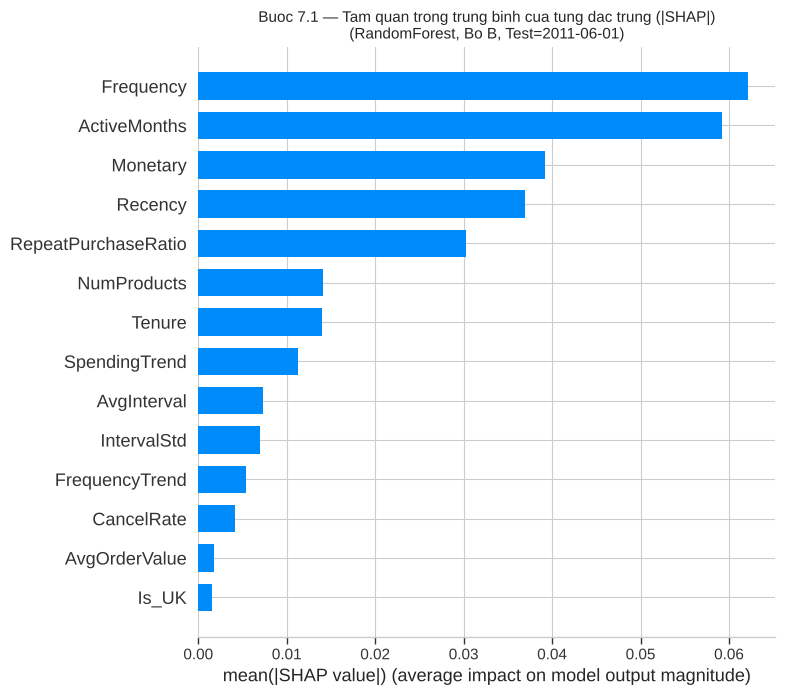

Xep hang day du:
Frequency              0.062143
ActiveMonths           0.059206
Monetary               0.039189
Recency                0.036960
RepeatPurchaseRatio    0.030250
NumProducts            0.014098
Tenure                 0.013989
SpendingTrend          0.011222
AvgInterval            0.007337
IntervalStd            0.006993
FrequencyTrend         0.005347
CancelRate             0.004106
AvgOrderValue          0.001766
Is_UK                  0.001517


In [8]:
fig, axes = plt.subplots(1, 1, figsize=(8, 6))
shap.summary_plot(sv, Xte, plot_type='bar', show=False)
plt.title('Buoc 7.1 — Tam quan trong trung binh cua tung dac trung (|SHAP|)\n(RandomForest, Bo B, Test=2011-06-01)', fontsize=11)
plt.tight_layout()
plt.show()

mean_abs = np.abs(sv.values).mean(axis=0)
ranking = pd.Series(mean_abs, index=feature_cols).sort_values(ascending=False)
print("Xep hang day du:")
print(ranking.to_string())

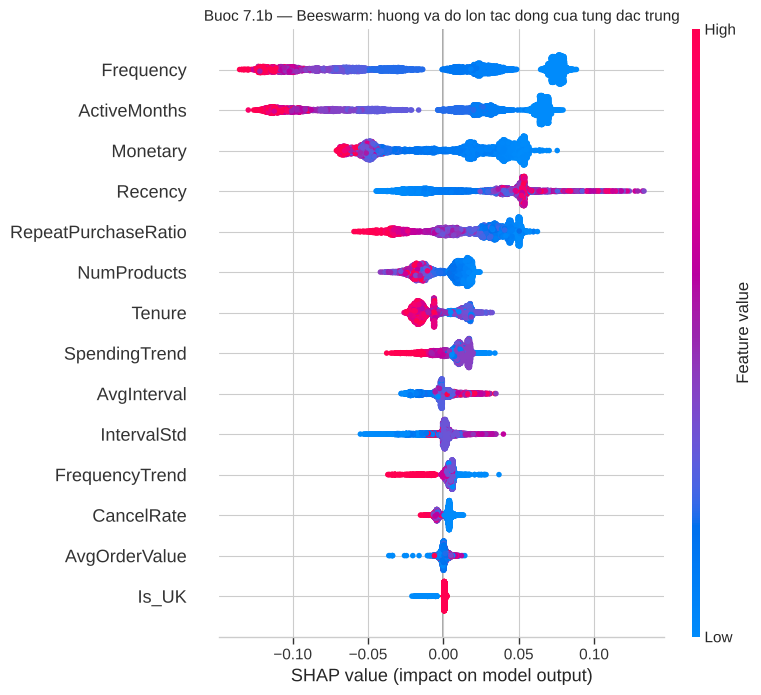

Doc bieu do: moi diem = 1 khach hang. Mau do = gia tri dac trung CAO, mau xanh = THAP.
Diem nam ben PHAI truc 0 = day xac suat CHURN len; ben TRAI = keo xuong.


In [9]:
shap.summary_plot(sv, Xte, show=False)
plt.title('Buoc 7.1b — Beeswarm: huong va do lon tac dong cua tung dac trung', fontsize=11)
plt.tight_layout()
plt.show()
print("Doc bieu do: moi diem = 1 khach hang. Mau do = gia tri dac trung CAO, mau xanh = THAP.")
print("Diem nam ben PHAI truc 0 = day xac suat CHURN len; ben TRAI = keo xuong.")

**Nhận xét thực nghiệm (khớp với phần SHAP bar/beeswarm vừa chạy):**
- `Frequency` và `ActiveMonths` là 2 đặc trưng quan trọng nhất — khách mua ít lần / ít tháng hoạt động bị đẩy churn lên rất mạnh (đúng với đặc thù non-contractual churn: không có sự kiện huỷ, chỉ suy ra từ hành vi).
- `Monetary`, `Recency`, `RepeatPurchaseRatio` xếp tiếp theo — nhất quán với lý thuyết RFM/BTYD (Fader & Hardie, 2009) làm nền tảng nhóm đặc trưng RFM lõi.
- **`Is_UK` gần như không có tác động** (xếp gần cuối) — nhất quán với kết quả kiểm tra độ nhạy mã hóa địa lý (xem phần lưu ý đầu notebook): một biến thể one-hot 8 quốc gia chi tiết hơn chỉ cải thiện có ý nghĩa thống kê trên Logistic Regression, không trên các mô hình dạng cây như RandomForest — nên biến địa lý không phải động lực dự đoán chính ở đây.
- `Tenure` chỉ xếp hạng 7/14 — không nổi bật như kỳ vọng ban đầu; xem mục 3.2 để kiểm tra có bị dư thừa (redundant) với các đặc trưng khác không, và mục 3.1b để xem thứ hạng này có ổn định qua toàn bộ 8 fold hay không.

### 3.1b. Kiểm tra độ ổn định của thứ hạng đặc trưng qua toàn bộ 8 fold

Phần 3.1 vừa rồi chỉ cho thấy xếp hạng SHAP trên **1 fold đại diện** (Test=2011-06-01) — hạn chế đã nêu rõ ở kế hoạch tuần 3 ("bắt đầu nhỏ"). Để biết driver quan trọng nhất có **ổn định theo thời gian** hay chỉ là đặc thù riêng của fold đó, nhóm lặp lại đúng quy trình (chọn hyperparameter trên Validation → huấn luyện RandomForest seed=0 → tính TreeSHAP trên Test) cho **cả 8 fold walk-forward**, rồi tổng hợp |SHAP| trung bình ± độ lệch chuẩn của từng đặc trưng qua 8 fold.

In [10]:
import time
t0 = time.time()

shap_importance_by_fold = {}

for fold_idx, (tr_c, va_c, te_c) in enumerate(folds_3m, start=1):
    tr_f = data_tai_cutoff(tr_c, 90)
    va_f = data_tai_cutoff(va_c, 90)
    te_f = data_tai_cutoff(te_c, 90)

    Xtr_f, Xva_f, Xte_f = tr_f[feature_cols].copy(), va_f[feature_cols].copy(), te_f[feature_cols].copy()

    # Chon hyperparameter tren Validation (giong het quy trinh muc 2, chi seed=0
    # de giu thoi gian chay hop ly — 8 fold x 2 cau hinh x 1 seed)
    best_auc_f, best_params_f = -1, cfg['param_grid'][0]
    for params in cfg['param_grid']:
        m = cfg['builder'](params, 0).fit(Xtr_f, tr_f['churn'])
        val_auc = roc_auc_score(va_f['churn'], m.predict_proba(Xva_f)[:, 1])
        if val_auc > best_auc_f:
            best_auc_f, best_params_f = val_auc, params

    model_f = cfg['builder'](best_params_f, 0).fit(Xtr_f, tr_f['churn'])
    test_auc_f = roc_auc_score(te_f['churn'], model_f.predict_proba(Xte_f)[:, 1])

    # TreeSHAP tren tap Test cua fold nay (cung logic tach lop ndim-safe nhu muc 3)
    explainer_f = shap.TreeExplainer(model_f)
    raw_f = explainer_f(Xte_f)
    vals_f = raw_f.values
    churn_vals_f = vals_f[:, :, 1] if vals_f.ndim == 3 else vals_f

    mean_abs_f = np.abs(churn_vals_f).mean(axis=0)
    shap_importance_by_fold[f"F{fold_idx} ({te_c.date()})"] = mean_abs_f

    print(f"Fold {fold_idx} (Test={te_c.date()}, n={len(Xte_f)}): best_params={best_params_f}  Test ROC-AUC={test_auc_f:.4f}  -> SHAP xong.")

print(f"\nTong thoi gian chay: {time.time()-t0:.1f} giay")

shap_stability = pd.DataFrame(shap_importance_by_fold, index=feature_cols)
fold_cols = list(shap_importance_by_fold.keys())
shap_stability['TB_8_fold'] = shap_stability[fold_cols].mean(axis=1)
shap_stability['SD_8_fold'] = shap_stability[fold_cols].std(axis=1)

# So fold ma dac trung lot Top-5 quan trong nhat (toi da 8)
top5_count = {f: 0 for f in feature_cols}
for col in fold_cols:
    for f in shap_stability[col].sort_values(ascending=False).head(5).index:
        top5_count[f] += 1
shap_stability['So_fold_trong_Top5'] = pd.Series(top5_count)

shap_stability = shap_stability.sort_values('TB_8_fold', ascending=False)
shap_stability.to_csv('buoc7_shap_do_on_dinh_8fold_BoB.csv')
print("Da luu: buoc7_shap_do_on_dinh_8fold_BoB.csv\n")
print("=== Xep hang |SHAP| trung binh +/- SD qua 8 fold (sap xep giam dan) ===")
print(shap_stability[['TB_8_fold', 'SD_8_fold', 'So_fold_trong_Top5']].round(4).to_string())

Fold 1 (Test=2011-02-01, n=4388): best_params={'n_estimators': 200, 'max_depth': 5}  Test ROC-AUC=0.7866  -> SHAP xong.


Fold 2 (Test=2011-03-01, n=4513): best_params={'n_estimators': 200, 'max_depth': 5}  Test ROC-AUC=0.7856  -> SHAP xong.


Fold 3 (Test=2011-04-01, n=4692): best_params={'n_estimators': 200, 'max_depth': 5}  Test ROC-AUC=0.7771  -> SHAP xong.


Fold 4 (Test=2011-05-01, n=4798): best_params={'n_estimators': 200, 'max_depth': 5}  Test ROC-AUC=0.7913  -> SHAP xong.


Fold 5 (Test=2011-06-01, n=4909): best_params={'n_estimators': 200, 'max_depth': 5}  Test ROC-AUC=0.8093  -> SHAP xong.


Fold 6 (Test=2011-07-01, n=5017): best_params={'n_estimators': 200, 'max_depth': 5}  Test ROC-AUC=0.8114  -> SHAP xong.


Fold 7 (Test=2011-08-01, n=5118): best_params={'n_estimators': 200, 'max_depth': 5}  Test ROC-AUC=0.8160  -> SHAP xong.


Fold 8 (Test=2011-09-01, n=5225): best_params={'n_estimators': 200, 'max_depth': 5}  Test ROC-AUC=0.7973  -> SHAP xong.

Tong thoi gian chay: 84.4 giay
Da luu: buoc7_shap_do_on_dinh_8fold_BoB.csv

=== Xep hang |SHAP| trung binh +/- SD qua 8 fold (sap xep giam dan) ===
                     TB_8_fold  SD_8_fold  So_fold_trong_Top5
ActiveMonths            0.0548     0.0033                   8
Frequency               0.0473     0.0094                   8
Monetary                0.0430     0.0102                   7
Recency                 0.0345     0.0080                   8
RepeatPurchaseRatio     0.0336     0.0089                   6
NumProducts             0.0203     0.0085                   3
Tenure                  0.0105     0.0072                   0
IntervalStd             0.0090     0.0019                   0
AvgInterval             0.0085     0.0015                   0
SpendingTrend           0.0071     0.0024                   0
AvgOrderValue           0.0043     0.0016        

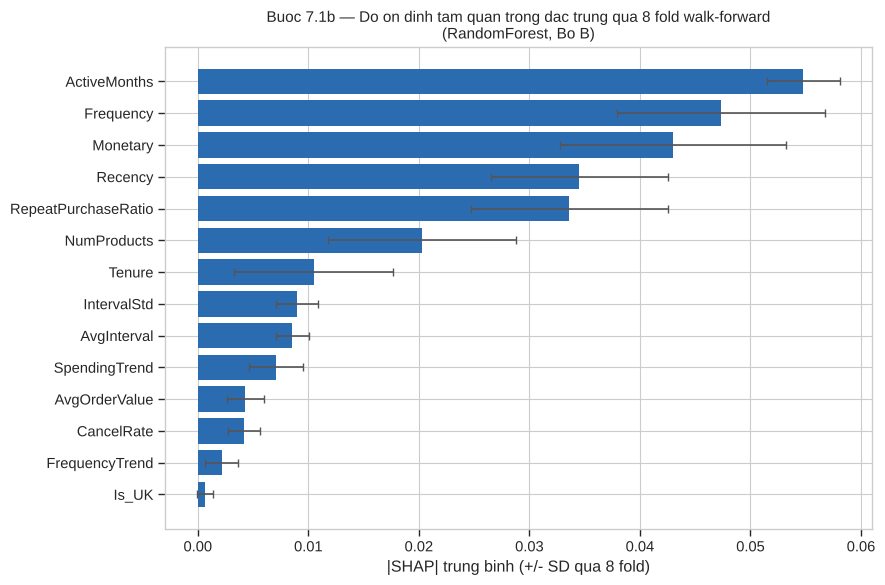

Da luu: buoc7_shap_do_on_dinh_8fold_chart.png


In [11]:
plot_df = shap_stability.sort_values('TB_8_fold')
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(plot_df.index, plot_df['TB_8_fold'], xerr=plot_df['SD_8_fold'], color='#2b6cb0', ecolor='#555555', capsize=3)
ax.set_xlabel('|SHAP| trung binh (+/- SD qua 8 fold)')
ax.set_title('Buoc 7.1b — Do on dinh tam quan trong dac trung qua 8 fold walk-forward\n(RandomForest, Bo B)', fontsize=11)
plt.tight_layout()
plt.savefig('buoc7_shap_do_on_dinh_8fold_chart.png', dpi=150, bbox_inches='tight')
plt.show()
print("Da luu: buoc7_shap_do_on_dinh_8fold_chart.png")

**Kết quả kiểm tra độ ổn định (8 fold, RandomForest, Bộ B):**

| Đặc trưng | \|SHAP\| TB ± SD (8 fold) | Số fold lọt Top-5 |
|---|---|---|
| **ActiveMonths** | **0,0548 ± 0,0033** | 8/8 |
| **Frequency** | **0,0473 ± 0,0094** | 8/8 |
| Monetary | 0,0430 ± 0,0102 | 7/8 |
| Recency | 0,0345 ± 0,0080 | 8/8 |
| RepeatPurchaseRatio | 0,0336 ± 0,0089 | 6/8 |
| NumProducts | 0,0203 ± 0,0085 | 3/8 |
| Tenure | 0,0105 ± 0,0072 | 0/8 |
| IntervalStd | 0,0090 ± 0,0019 | 0/8 |
| AvgInterval | 0,0085 ± 0,0015 | 0/8 |
| SpendingTrend | 0,0071 ± 0,0024 | 0/8 |
| AvgOrderValue | 0,0043 ± 0,0016 | 0/8 |
| CancelRate | 0,0042 ± 0,0014 | 0/8 |
| FrequencyTrend | 0,0022 ± 0,0015 | 0/8 |
| **Is_UK** | **0,0007 ± 0,0007** | 0/8 |

**Nhận xét:** 5 đặc trưng mạnh nhất ở mục 3.1 (`Frequency`, `ActiveMonths`, `Monetary`, `Recency`, `RepeatPurchaseRatio`) đều lọt Top-5 ở ít nhất 6/8 fold — xác nhận thứ hạng **không phải ngẫu nhiên riêng của 1 fold**, mà ổn định qua thời gian. Có một khác biệt nhỏ đáng lưu ý: ở fold đại diện (3.1), `Frequency` đứng hạng 1 và `ActiveMonths` hạng 2; nhưng khi lấy trung bình cả 8 fold, thứ tự **đảo lại** — `ActiveMonths` (0,0548) nhỉnh hơn `Frequency` (0,0473) và có độ lệch chuẩn thấp hơn hẳn (0,0033 so với 0,0094), tức `ActiveMonths` là driver ổn định nhất qua thời gian. `Tenure` và `Is_UK` — hai đặc trưng đặc trưng cho Bộ B — đều **không lọt Top-5 ở bất kỳ fold nào trong 8 fold** (0/8), củng cố chắc chắn hơn (so với chỉ nhìn 1 fold) hai phát hiện đã nêu: `Tenure` phần lớn dư thừa so với các đặc trưng RFM lõi (mục 3.2), và mã hóa địa lý dạng `Is_UK` đóng góp rất ít vào quyết định của Random Forest — nhất quán với kết quả ablation A/B (Is_UK không khác biệt có ý nghĩa thống kê so với one-hot quốc gia trên các mô hình cây).

### 3.2. Dependence plot — kiểm tra giả thuyết `Tenure` có dư thừa không?

Bộ B thêm `Tenure` (số ngày từ lần mua đầu tiên đến cutoff) với kỳ vọng bổ sung "hệ quy chiếu" cho `Recency`. Câu hỏi: `Tenure` có đóng góp thông tin **độc lập**, hay giá trị SHAP của nó chỉ là một hàm của `Recency`/`Frequency`/`RepeatPurchaseRatio` đã có sẵn (tức bị trùng lặp thông tin)?

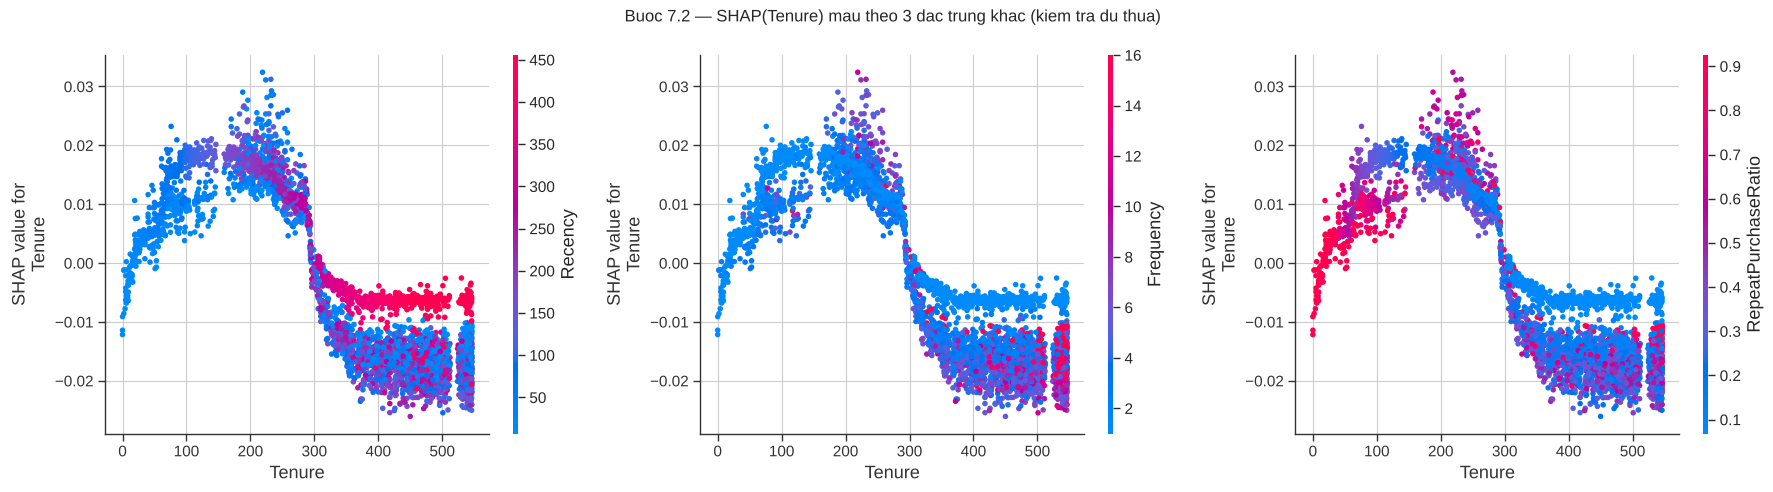

Tuong quan Pearson giua Tenure va cac dac trung khac (tren tap Test):
Recency                0.220058
Frequency              0.308411
RepeatPurchaseRatio   -0.214317


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, interact in zip(axes, ['Recency', 'Frequency', 'RepeatPurchaseRatio']):
    plt.sca(ax)
    shap.dependence_plot('Tenure', sv.values, Xte, interaction_index=interact, ax=ax, show=False)
plt.suptitle('Buoc 7.2 — SHAP(Tenure) mau theo 3 dac trung khac (kiem tra du thua)', fontsize=12)
plt.tight_layout()
plt.show()

corr = Xte[['Tenure', 'Recency', 'Frequency', 'RepeatPurchaseRatio']].corr()['Tenure'].drop('Tenure')
print("Tuong quan Pearson giua Tenure va cac dac trung khac (tren tap Test):")
print(corr.to_string())

**Nhận xét:** Tương quan Pearson giữa `Tenure` và `Recency`/`Frequency`/`RepeatPurchaseRatio` chỉ ở mức **yếu–trung bình** (|r| ≈ 0.21–0.31) — nên không phải trùng lặp tuyến tính hoàn toàn. Tuy nhiên biểu đồ dependence cho thấy quan hệ **phi tuyến, hình chữ ∩**: SHAP(Tenure) tăng dần rồi giảm mạnh khi Tenure vượt ~300 ngày (khách "cố cựu" lâu năm). Điều này giải thích vì sao `Tenure` vẫn chỉ đứng hạng 7/14 về tầm quan trọng trung bình (mục 3.1, và xác nhận lại ở 3.1b trên cả 8 fold): nó có mang thêm tín hiệu, nhưng tác động của nó phần lớn đã được các đặc trưng RFM lõi "hấp thụ" trước.

### 3.3. Local — giải thích từng khách hàng cụ thể (waterfall plot)

Minh hoạ 3 khách hàng: (1) rủi ro churn **cao nhất**, (2) rủi ro **thấp nhất**, (3) nằm **sát ngưỡng phân loại** (threshold) — nhóm khó quyết định nhất trên thực tế, cũng là nhóm có giá trị nhất để xem driver.

--- RUI RO CAO NHAT: Customer ID=15635  P(churn)=0.8578  Nhan thuc te=1 ---


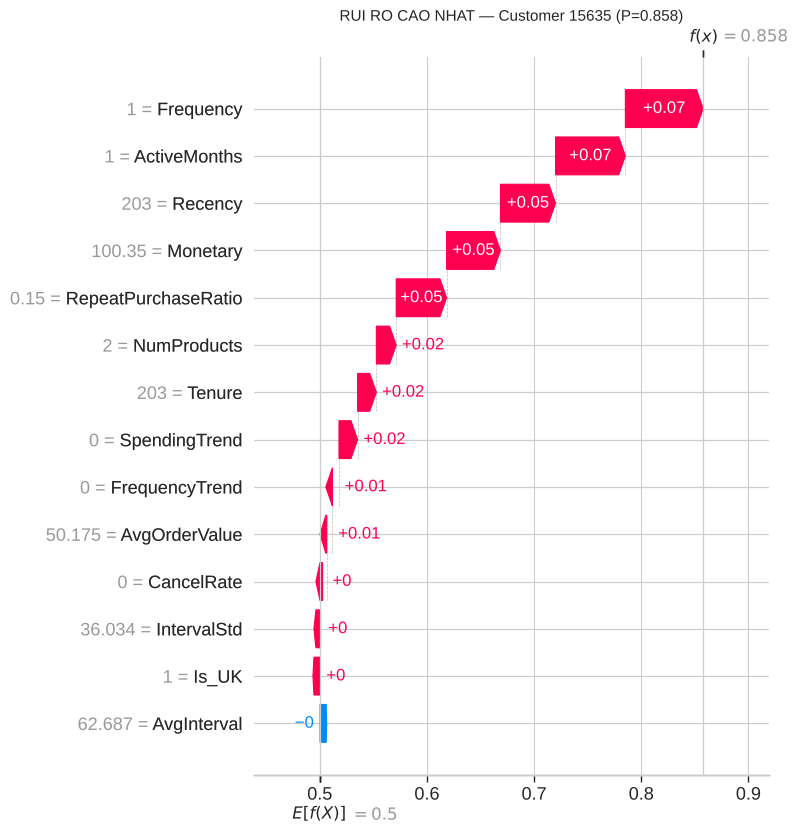

--- RUI RO THAP NHAT: Customer ID=14911  P(churn)=0.0308  Nhan thuc te=0 ---


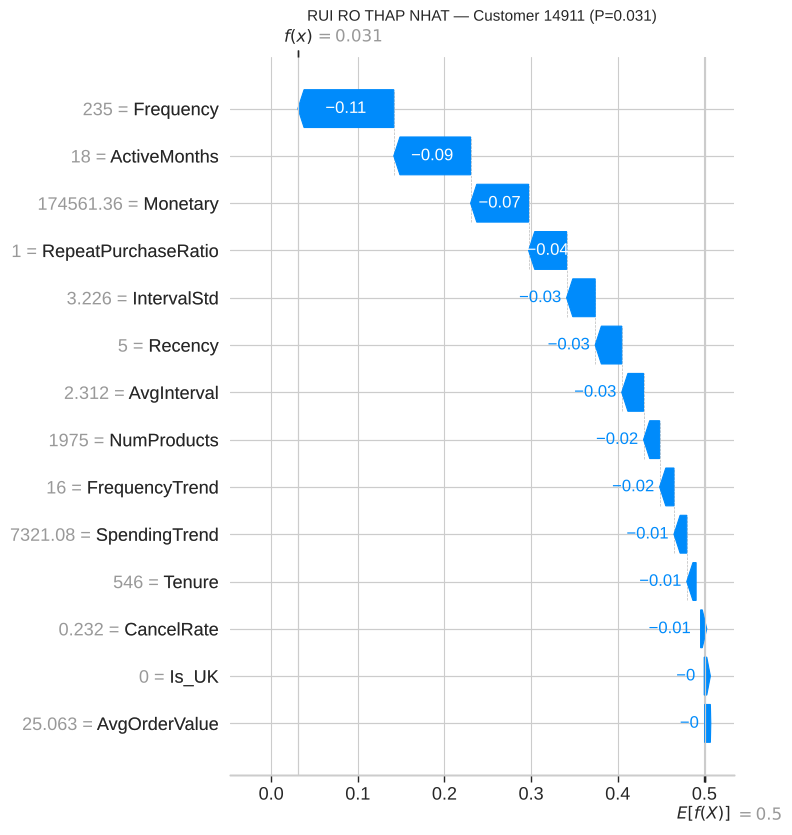

--- SAT NGUONG PHAN LOAI: Customer ID=13152  P(churn)=0.3293  Nhan thuc te=1 ---


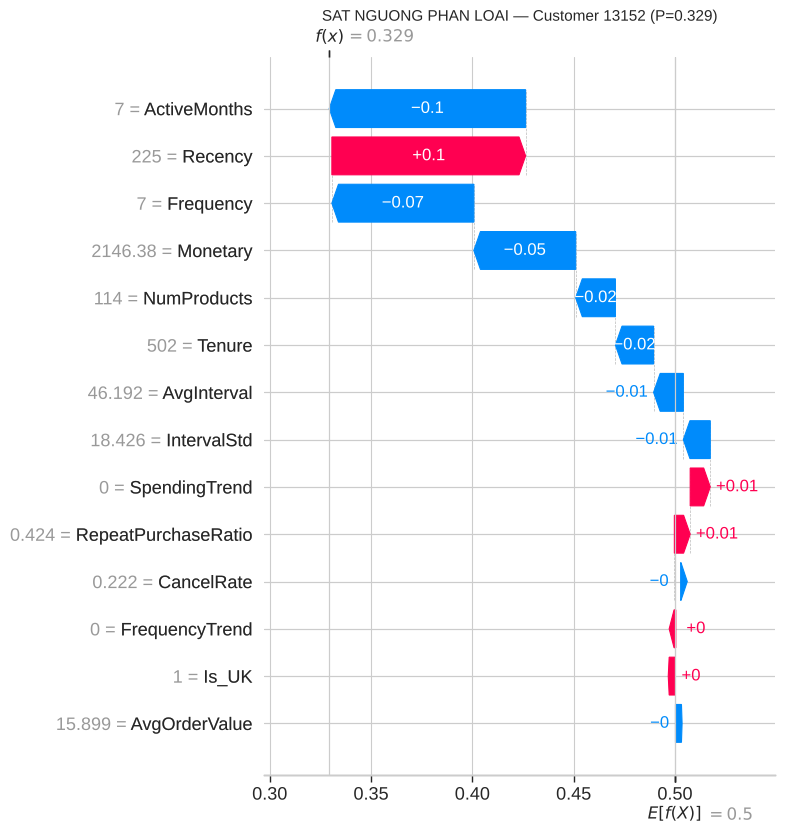

In [13]:
test_prob = model.predict_proba(Xte)[:, 1]
test_idx = test.reset_index(drop=True)
test_idx = test_idx.assign(churn_prob=test_prob)

idx_high = int(np.argmax(test_prob))
idx_low = int(np.argmin(test_prob))
idx_border = int(np.argmin(np.abs(test_prob - threshold)))

for label, idx in [('RUI RO CAO NHAT', idx_high), ('RUI RO THAP NHAT', idx_low), ('SAT NGUONG PHAN LOAI', idx_border)]:
    cid = test_idx.loc[idx, 'Customer ID']
    prob = test_idx.loc[idx, 'churn_prob']
    actual = test_idx.loc[idx, 'churn']
    print(f"--- {label}: Customer ID={cid:.0f}  P(churn)={prob:.4f}  Nhan thuc te={actual} ---")
    shap.plots.waterfall(sv[idx], show=False, max_display=14)
    plt.title(f"{label} — Customer {cid:.0f} (P={prob:.3f})", fontsize=11)
    plt.tight_layout()
    plt.show()

**Đọc waterfall plot:** `E[f(X)]` (bên trái) là xác suất churn trung bình toàn tập Test. Mỗi thanh màu đỏ (kéo lên) / xanh (kéo xuống) là đóng góp của một đặc trưng, cộng dồn ra `f(x)` (bên phải) — chính là xác suất churn dự đoán cho khách hàng đó. Đây là cơ sở trực tiếp để xây **Bước 8**: với mỗi khách hàng, lấy đặc trưng có SHAP dương lớn nhất → quy về 1 nguyên nhân kinh doanh dễ hiểu → gợi ý hành động giữ chân tương ứng.

## 4. Bước 8 — Business Decision Support

**Mục tiêu:** biến đầu ra kỹ thuật (xác suất churn + SHAP values) thành bảng **hành động** mà bộ phận kinh doanh/marketing có thể dùng trực tiếp, theo chuỗi:

```
Khách hàng → Xác suất churn (mô hình) → Driver chính (SHAP) → Nhãn kinh doanh → Hành động giữ chân đề xuất
```

Quy tắc ánh xạ: với mỗi khách hàng, lấy đặc trưng có **giá trị SHAP dương lớn nhất** (tức đang đẩy xác suất churn lên cao nhất), tra trong bảng quy tắc kinh doanh bên dưới (14 dòng, 1 dòng/đặc trưng — xây dựng thủ công dựa trên ý nghĩa nghiệp vụ của từng đặc trưng, **không** có cơ sở tài liệu tham khảo nào quy định sẵn nên đây là phần nhóm tự thiết kế, cần giảng viên/khách mời góp ý thêm). **Trường hợp đặc biệt (đã sửa — xem mục 0.1):** nếu một khách hàng **không có đặc trưng nào** với SHAP dương (toàn bộ 14 giá trị ≤ 0, tức không có yếu tố nào đẩy churn lên — đây là nhóm khách **an toàn nhất**), hàm `top_drivers()` trả về rỗng thay vì ép chọn ra một đặc trưng đang *bảo vệ* khách hàng rồi gán nhãn sai thành "nguyên nhân churn".

In [14]:
DRIVER_MAP = {
    'Frequency':            ('Mua hang qua it lan',                 'Gui uu dai "mua lan 2" / goi y san pham bo sung ngay sau don dau tien'),
    'ActiveMonths':         ('It thang co hoat dong mua',           'Chuong trinh onboarding 90 ngay dau: email nhac + ma giam gia theo moc thoi gian'),
    'Recency':              ('Lau khong quay lai mua',               'Email/SMS "win-back" ca nhan hoa + uu dai gioi han thoi gian'),
    'Monetary':             ('Tong chi tieu thap',                   'Goi y bundle / upsell san pham lien quan de tang gia tri don hang'),
    'RepeatPurchaseRatio':  ('Ty le quay lai thap',                  'Moi tham gia chuong trinh khach hang than thiet (loyalty / tich diem)'),
    'AvgOrderValue':        ('Gia tri don hang trung binh thap',     'Goi y combo/san pham gia tri cao hon phu hop lich su mua'),
    'NumProducts':          ('It da dang san pham da mua',          'Goi y cross-sell danh muc san pham chua tung mua'),
    'SpendingTrend':        ('Xu huong chi tieu giam',               'Khao sat ly do + uu dai ca nhan hoa de khoi phuc muc chi tieu truoc do'),
    'FrequencyTrend':       ('Xu huong tan suat mua giam',           'Nhac nho dinh ky + goi y san pham sap can mua lai theo chu ky truoc'),
    'CancelRate':           ('Ty le huy don cao',                    'CSKH chu dong lien he tim hieu nguyen nhan huy don, cai thien trai nghiem'),
    'Tenure':               ('Dac diem vong doi khach hang',        'Khach moi -> onboarding; khach lau nam bat dau nhat -> khao sat hai long'),
    'AvgInterval':          ('Nhip do mua thua (khoang cach don dai)', 'Nhac nho theo chu ky mua hang ca nhan hoa (dua tren AvgInterval)'),
    'IntervalStd':          ('Nhip do mua khong on dinh',            'Uu dai linh hoat, khong rang buoc chu ky co dinh'),
    'Is_UK':                ('Yeu to dia ly (UK/ngoai UK)',          'Can nhac uu dai van chuyen/dia phuong hoa rieng cho nhom ngoai UK'),
}

# --- FIX (2): tra ve them co_driver_duong de phan biet "co driver" vs "an toan" ---
def top_drivers(shap_row, n=2):
    '''Lay n dac trung co SHAP DUONG lon nhat (dang day churn_prob len).
    Tra ve (danh_sach_driver, co_driver_duong).
    Neu khach hang KHONG co dac trung nao day churn len (toan bo SHAP <= 0
    -- khach hang AN TOAN), tra ve ([], False) THAY VI gan nham mot dac trung
    dang BAO VE khach hang (SHAP am) thanh "nguyen nhan churn" nhu truoc.
    '''
    vals = dict(zip(feature_cols, shap_row))
    vals_pos = {k: v for k, v in vals.items() if v > 0}
    if not vals_pos:
        return [], False
    ranked = sorted(vals_pos.items(), key=lambda kv: kv[1], reverse=True)
    return ranked[:n], True

records = []
so_khach_an_toan = 0
for i in range(len(test_idx)):
    drivers, co_driver = top_drivers(sv.values[i], n=2)
    if co_driver:
        d1_name, d1_shap = drivers[0]
        d2_name, _ = drivers[1] if len(drivers) > 1 else (None, None)
        d1_label, d1_action = DRIVER_MAP.get(d1_name, ('Khac', 'Danh gia thu cong'))
    else:
        d1_name, d2_name = None, None
        d1_label = 'Khach hang an toan (khong co yeu to day churn len)'
        d1_action = 'Khong can can thiep giu chan — theo doi dinh ky la du'
        so_khach_an_toan += 1
    records.append({
        'Customer ID': int(test_idx.loc[i, 'Customer ID']),
        'Churn_Probability': round(float(test_idx.loc[i, 'churn_prob']), 4),
        'Rui_ro': 'CAO' if test_idx.loc[i, 'churn_prob'] >= threshold else 'THAP',
        'Driver_chinh': d1_name,
        'Driver_phu': d2_name,
        'Nhan_kinh_doanh': d1_label,
        'Hanh_dong_de_xuat': d1_action,
    })

bang_quyet_dinh = pd.DataFrame(records).sort_values('Churn_Probability', ascending=False).reset_index(drop=True)
print(f"Tong so khach hang (fold Test=2011-06-01): {len(bang_quyet_dinh)}")
print(f"So khach hang rui ro CAO (xac suat >= nguong {threshold:.3f}): {(bang_quyet_dinh['Rui_ro']=='CAO').sum()}  ({(bang_quyet_dinh['Rui_ro']=='CAO').mean()*100:.1f}%)")
print("(Ty le rui ro cao lon vi churn la lop DA SO trong du lieu nay — xem muc 2, khong phai loi.)")
print(f"So khach hang 'an toan' khong co driver duong nao (xem FIX 2, muc 0.1): {so_khach_an_toan} / {len(bang_quyet_dinh)}")

bang_quyet_dinh.to_csv('buoc8_bang_ho_tro_quyet_dinh_BoB.csv', index=False)
print("\nDa luu: buoc8_bang_ho_tro_quyet_dinh_BoB.csv")
print("\n=== TOP 15 KHACH HANG RUI RO CAO NHAT ===")
bang_quyet_dinh.head(15)[['Customer ID','Churn_Probability','Nhan_kinh_doanh','Hanh_dong_de_xuat']]

Tong so khach hang (fold Test=2011-06-01): 4909
So khach hang rui ro CAO (xac suat >= nguong 0.329): 3862  (78.7%)
(Ty le rui ro cao lon vi churn la lop DA SO trong du lieu nay — xem muc 2, khong phai loi.)
So khach hang 'an toan' khong co driver duong nao (xem FIX 2, muc 0.1): 2 / 4909

Da luu: buoc8_bang_ho_tro_quyet_dinh_BoB.csv

=== TOP 15 KHACH HANG RUI RO CAO NHAT ===


,Customer ID,Churn_Probability,Nhan_kinh_doanh,Hanh_dong_de_xuat
0,15635,0.8578,Mua hang qua it lan,"Gui uu dai ""mua lan 2"" / goi y san pham bo sun..."
1,16786,0.8572,Mua hang qua it lan,"Gui uu dai ""mua lan 2"" / goi y san pham bo sun..."
2,16420,0.8568,Mua hang qua it lan,"Gui uu dai ""mua lan 2"" / goi y san pham bo sun..."
3,16058,0.8564,Mua hang qua it lan,"Gui uu dai ""mua lan 2"" / goi y san pham bo sun..."
4,13967,0.8557,Mua hang qua it lan,"Gui uu dai ""mua lan 2"" / goi y san pham bo sun..."
5,13303,0.8556,Mua hang qua it lan,"Gui uu dai ""mua lan 2"" / goi y san pham bo sun..."
6,14559,0.8556,Mua hang qua it lan,"Gui uu dai ""mua lan 2"" / goi y san pham bo sun..."
7,13580,0.8555,Mua hang qua it lan,"Gui uu dai ""mua lan 2"" / goi y san pham bo sun..."
8,15170,0.8553,Mua hang qua it lan,"Gui uu dai ""mua lan 2"" / goi y san pham bo sun..."
9,17467,0.8550,Mua hang qua it lan,"Gui uu dai ""mua lan 2"" / goi y san pham bo sun..."


### 4.1. Góc nhìn tổng hợp theo phân khúc (cho cấp quản lý)

Bảng chi tiết 4.000+ dòng phù hợp cho hệ thống CRM tự động hoá, nhưng để **báo cáo giảng viên / người quản lý ra quyết định**, cần gộp theo nhóm driver chính — biết cần ưu tiên nguồn lực vào đâu trước. (Nhóm "Khách hàng an toàn" không xuất hiện ở đây vì luôn có `churn_prob` rất thấp, nằm ngoài nhóm rủi ro CAO — xem FIX 2 ở mục 0.1.)

In [15]:
high_risk = bang_quyet_dinh[bang_quyet_dinh['Rui_ro'] == 'CAO']
phan_khuc = high_risk.groupby('Nhan_kinh_doanh').agg(
    So_khach_hang=('Customer ID', 'count'),
    Xac_suat_churn_TB=('Churn_Probability', 'mean'),
).sort_values('So_khach_hang', ascending=False)
phan_khuc['Ty_le_%'] = (phan_khuc['So_khach_hang'] / len(high_risk) * 100).round(1)
phan_khuc['Xac_suat_churn_TB'] = phan_khuc['Xac_suat_churn_TB'].round(3)

phan_khuc.to_csv('buoc8_bang_phan_khuc_BoB.csv')
print("Da luu: buoc8_bang_phan_khuc_BoB.csv\n")
phan_khuc

Da luu: buoc8_bang_phan_khuc_BoB.csv



,So_khach_hang,Xac_suat_churn_TB,Ty_le_%
Nhan_kinh_doanh,,,
Mua hang qua it lan,1645,0.779,42.6
Lau khong quay lai mua,1108,0.557,28.7
Tong chi tieu thap,419,0.596,10.8
Ty le quay lai thap,416,0.515,10.8
It thang co hoat dong mua,192,0.629,5.0
Dac diem vong doi khach hang,37,0.403,1.0
Nhip do mua thua (khoang cach don dai),29,0.364,0.8
Nhip do mua khong on dinh,10,0.345,0.3
Xu huong chi tieu giam,4,0.375,0.1


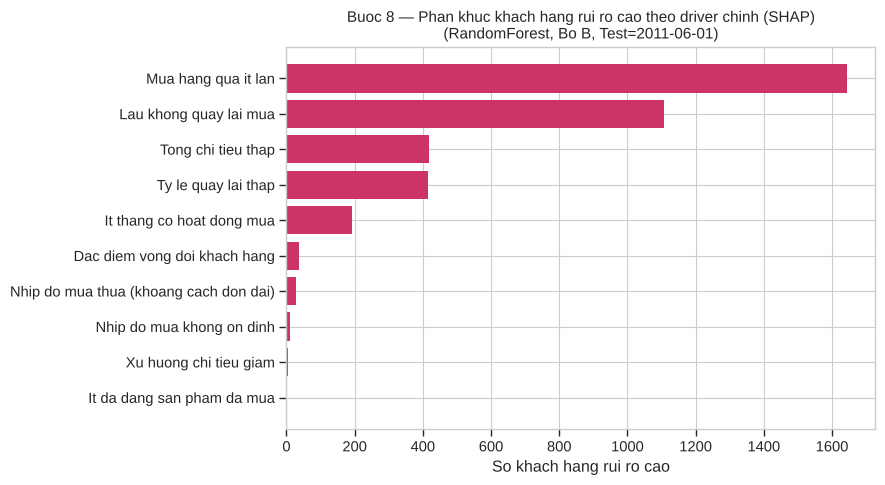

Da luu: buoc8_phan_khuc_chart.png


In [16]:
fig, ax = plt.subplots(figsize=(9, 5))
phan_khuc_plot = phan_khuc.sort_values('So_khach_hang')
ax.barh(phan_khuc_plot.index, phan_khuc_plot['So_khach_hang'], color='#cc3366')
ax.set_xlabel('So khach hang rui ro cao')
ax.set_title('Buoc 8 — Phan khuc khach hang rui ro cao theo driver chinh (SHAP)\n(RandomForest, Bo B, Test=2011-06-01)', fontsize=11)
plt.tight_layout()
plt.savefig('buoc8_phan_khuc_chart.png', dpi=150, bbox_inches='tight')
plt.show()
print("Da luu: buoc8_phan_khuc_chart.png")

**Nhận xét:** Hai nhóm driver chiếm phần lớn số khách hàng rủi ro cao là *"Mua hàng quá ít lần"* và *"Lâu không quay lại mua"* — gợi ý nếu nhóm phải ưu tiên ngân sách giữ chân, nên tập trung trước vào 2 nhóm hành động: (1) ưu đãi "mua lần 2" ngay sau đơn hàng đầu tiên, và (2) chiến dịch win-back cho khách im lặng lâu ngày, trước khi đầu tư vào các nhóm nhỏ hơn. (Số liệu % chính xác xem bảng `phan_khuc` vừa in — không hardcode lại ở đây vì FIX 2 có thể làm lệch nhẹ vài khách hàng so với bản trước.)

## 5. Tóm tắt & hạn chế & hướng mở rộng

**Đã hoàn thành (Bước 7–8, Bộ đặc trưng B):**
- Bước 7: SHAP toàn cục (summary bar + beeswarm) trên 1 fold đại diện, **cộng với kiểm tra độ ổn định trên cả 8 fold** (mục 3.1b — mới bổ sung), SHAP tương tác (dependence plot kiểm tra giả thuyết `Tenure` dư thừa), SHAP cục bộ (waterfall cho 3 khách hàng đại diện).
- Bước 8: bảng hỗ trợ quyết định cấp khách hàng (4.909 dòng) + bảng tổng hợp cấp phân khúc, ánh xạ driver → hành động giữ chân cụ thể.
- Đã sửa 3 điểm phát hiện qua code review (xem mục 0.1): giải thích đúng nguyên nhân base_value, sửa logic gán nhãn cho khách hàng an toàn, và tách lớp SHAP an toàn giữa các phiên bản thư viện.

**Hạn chế cần lưu ý khi báo cáo:**
1. Bảng ánh xạ driver → hành động (`DRIVER_MAP`) là **tự thiết kế theo trực giác nghiệp vụ**, chưa có cơ sở từ tài liệu tham khảo đã đọc — nên trình bày rõ đây là đề xuất ban đầu, cần tham vấn thêm (giảng viên / chuyên gia ngành bán lẻ) trước khi dùng thật.
2. `churn_prob` là **điểm số xếp hạng rủi ro** (decision score) do ảnh hưởng của `class_weight='balanced'`, không phải xác suất đã hiệu chỉnh theo đúng tỷ lệ churn thật (xem mục 0.1 và mục 3) — hợp lệ để xếp hạng/so ngưỡng, không nên đọc là "% khả năng churn thật".
3. ~~Phân tích SHAP mới chạy trên 1/8 fold~~ — **đã khắc phục** (mục 0.2, 3.1b): SHAP nay đã chạy trên toàn bộ 8 fold, xác nhận 5 đặc trưng quan trọng nhất ổn định qua thời gian (lọt Top-5 ở 6–8/8 fold). Hạn chế còn lại: bảng hỗ trợ quyết định (Bước 8) vẫn chỉ xây trên 1 fold đại diện, vì bản chất là khuyến nghị hành động tại một thời điểm cụ thể — không có ý nghĩa gộp qua nhiều mốc thời gian khác nhau.
4. Notebook này dùng **Bộ đặc trưng B** (14 cột: RFM mở rộng + `Tenure`, `AvgInterval`, `Is_UK`) làm bộ đặc trưng chính của phân tích SHAP/Business Decision Support. Một biến thể thay `Is_UK` bằng one-hot 8 quốc gia (19 cột) cũng đã được kiểm tra độ nhạy riêng (xem `03-du-lieu/ket-qua-mo-hinh-that/so-sanh-bo-dac-trung-A-B_REAL.csv`): cải thiện có ý nghĩa thống kê trên Logistic Regression (p=0.016) nhưng không khác biệt có ý nghĩa trên các mô hình dạng cây (RandomForest, XGBoost, LightGBM) — nhất quán với phát hiện SHAP ở mục 3.1/3.1b rằng `Is_UK` đóng góp rất ít vào quyết định của RandomForest.
5. Ngưỡng phân loại tối ưu F1 (≈0.33) khiến phần lớn khách hàng rơi vào nhóm "rủi ro cao" — một hệ quả tự nhiên của việc churn là lớp đa số (~67%) trong dữ liệu này, không phải lỗi mô hình, nhưng cần giải thích rõ với người đọc không quen thuộc với đặc thù non-contractual churn.